In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("..")

import ast
import json
from pathlib import Path
import numpy as np
import xarray as xr
import rioxarray as rxr
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid", {"grid.color": ".93"})

from src.load_data import extract_adjusted_timesteps, ClimateData

In [3]:
paths = json.load(open("../paths.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_figs = Path(paths["path_figs"])

# Load data

In [4]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

institute = climate_model_chain.split("-")[0]
rcm = climate_model_chain.split("_")[0]
gcm = climate_model_chain.split("_")[1]
ensemble = climate_model_chain.split("_")[-1]

## 1. Load linearized mapping of years to adjust warming trend of EURO-CORDEX model

In [5]:
df_climate_models_mapping = pd.read_csv(path_data_adjusted_cordex / "year_lists.csv")
df_climate_models_mapping["year_list"] = [ast.literal_eval(l) for l in df_climate_models_mapping["year_list"]]

adjusted_timesteps = extract_adjusted_timesteps(df_climate_models_mapping, climate_model_chain, climate_scenario)

## 2. Load climate data

In [6]:
variable = "tas"
temp_res = "3hr"

cordex_tas = path_data_cordex / climate_scenario / temp_res / variable / institute / gcm / rcm / ensemble
cordex_tas_hist = path_data_cordex / "historical" / temp_res / variable / institute / gcm / rcm / ensemble

In [7]:
extent = {
    "lat_min": 45,
    "lat_max": 48,
    "lon_min": 5.8, 
    "lon_max": 10.8
}

In [8]:
climate_data = ClimateData(cordex_tas, cordex_tas_hist, adjusted_timesteps, chunks=None, extent=extent)

/home/yhaddad/.conda/envs/bias_correction_2023/lib/python3.11/site-packages/xarray/core/indexing.py:1621: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]
/home/yhaddad/.conda/envs/bias_correction_2023/lib/python3.11/site-packages/xarray/core/indexing.py:1621: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]

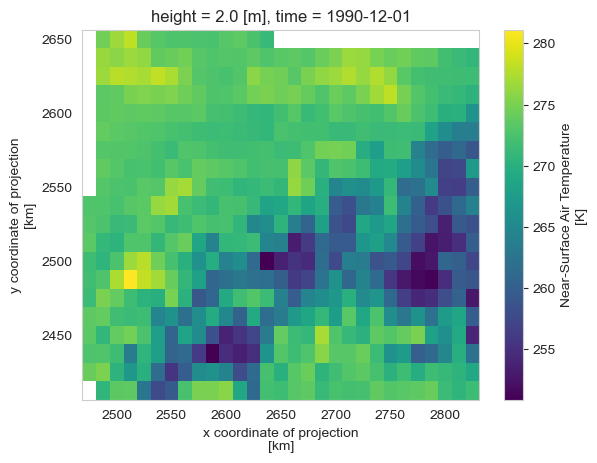

In [60]:
climate_data.ds_data.isel(time=0).tas.plot()